In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = {
    "Area": [2400, 2700, 3000, 3400, 4000],
    "Price": [5500000, 6100000, 6500000, 6800000, 7200000]
}

df = pd.DataFrame(data)

df


,Area,Price
0,2400,5500000
1,2700,6100000
2,3000,6500000
3,3400,6800000
4,4000,7200000


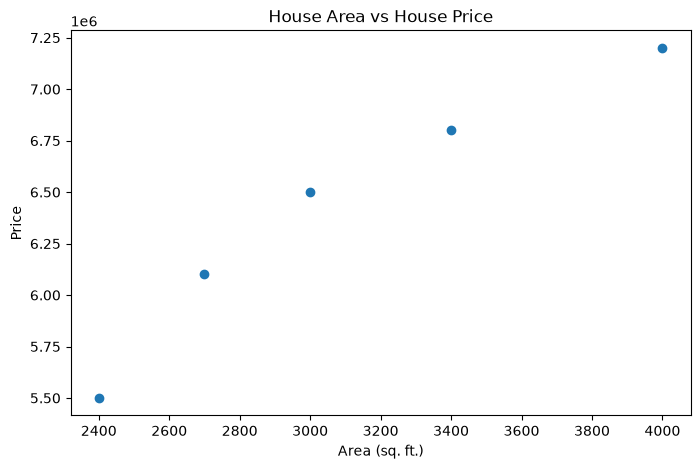

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Area"], df["Price"])
plt.xlabel("Area (sq. ft.)")
plt.ylabel("Price")
plt.title("House Area vs House Price")
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression

# Reshape X as 2D feature matrix and y as 1D target vector
X = df[["Area"]]
y = df["Price"]

model = LinearRegression()
model.fit(X, y)

slope = model.coef_[0]
intercept = model.intercept_
print(f"Fitted Slope (m): {slope:,.2f}")
print(f"Fitted Intercept (c): {intercept:,.2f}")
print(f"Regression Formula: Price = {slope:,.2f} * Area + {intercept:,.2f}")


Fitted Slope (m): 1,012.82
Fitted Intercept (c): 3,280,256.41
Regression Formula: Price = 1,012.82 * Area + 3,280,256.41


In [5]:
# Predict house prices for unseen sizes: 3,200 sq.ft and 4,500 sq.ft
new_areas = pd.DataFrame({"Area": [3200, 4500]})
predicted_prices = model.predict(new_areas)

for area, price in zip(new_areas["Area"], predicted_prices):
    print(f"Predicted price for {area:,} sq.ft house: ${price:,.2f}")


Predicted price for 3,200 sq.ft house: $6,521,282.05
Predicted price for 4,500 sq.ft house: $7,837,948.72


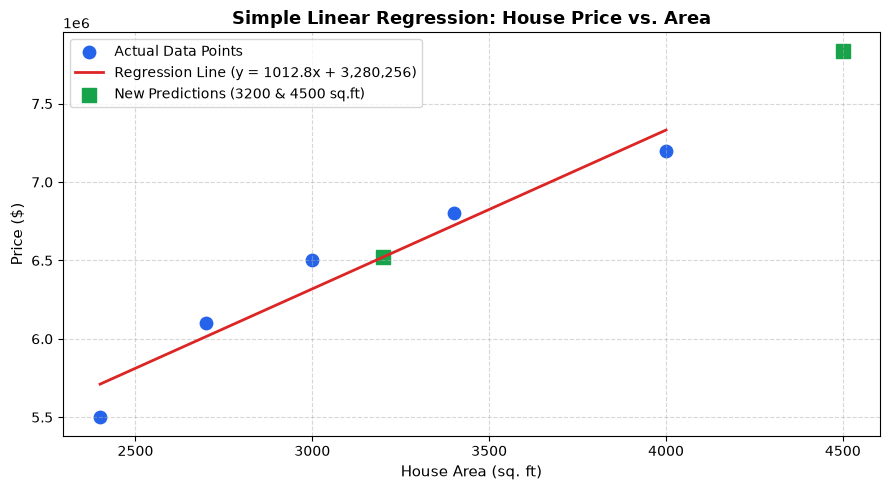

In [6]:
plt.figure(figsize=(9, 5))
plt.scatter(df["Area"], df["Price"], color="#2563eb", s=80, label="Actual Data Points")
plt.plot(df["Area"], model.predict(X), color="#dc2626", linewidth=2, label=f"Regression Line (y = {slope:.1f}x + {intercept:,.0f})")
plt.scatter(new_areas["Area"], predicted_prices, color="#16a34a", marker="s", s=100, label="New Predictions (3200 & 4500 sq.ft)")

plt.xlabel("House Area (sq. ft)", fontsize=11)
plt.ylabel("Price ($)", fontsize=11)
plt.title("Simple Linear Regression: House Price vs. Area", fontsize=13, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
